# Predictive AI Model for Smart Energy Management and Real-Time Load Balancing
**Capstone project - Progress demo (Steps 2 to 8 of 10 completed)**

| Step | Work | Status |
|---|---|---|
| 1 | Problem statement and architecture | Done (report/slides) |
| 2 | Data loading | **Done (this notebook)** |
| 3 | Data cleaning and preprocessing | **Done (this notebook)** |
| 4 | Exploratory analysis (usage patterns) | **Done (this notebook)** |
| 5 | Feature engineering and train/test split | **Done (this notebook)** |
| 6 | AI prediction models and comparison | **Done (this notebook)** |
| 7 | Real-time load balancing (solar + battery) | **Done (this notebook)** |
| 8 | Results: peak reduction and cost saving | **Done (this notebook)** |
| 9 | Dashboard (Streamlit) | Planned |
| 10 | Real dataset, LSTM model, testing, final report | Planned |

**Architecture:** Data -> Cleaning -> Features -> Prediction model -> Load balancing -> Results

*Note: this demo runs on realistic SAMPLE data. Step 10 replaces it with the real UCI dataset.*

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True
print("Libraries loaded successfully")

Libraries loaded successfully


## Step 2: Data loading
We need hourly electricity consumption (in kW). The real dataset (UCI Household Electric Power Consumption) will be
used in the final version. For now we generate **one full year of realistic hourly data**
(daily cycle, weekend effect, seasonal effect, noise) to build and test the whole pipeline.

In [2]:
USE_REAL_DATA = False                       # set True later and give the file path
REAL_DATA_PATH = "household_power_consumption.txt"

def make_sample_data(days=365, seed=42):
    rng = np.random.default_rng(seed)
    t = pd.date_range("2024-01-01", periods=24 * days, freq="h")
    hour, dow, doy = t.hour.values, t.dayofweek.values, t.dayofyear.values
    morning = 1.0 * np.exp(-((hour - 7.5) ** 2) / 4)          # morning usage
    evening = 2.2 * np.exp(-((hour - 20) ** 2) / 6)           # evening peak
    weekend = np.where(dow >= 5, 0.35 * np.exp(-((hour - 13) ** 2) / 20), 0)
    season = 0.6 * np.cos((doy - 200) / 365 * 2 * np.pi)      # summer usage
    noise = rng.normal(0, 0.18, len(t))
    load = np.clip(0.8 + morning + evening + weekend + season + noise, 0.2, None)
    return pd.DataFrame({"time": t, "load": load})

def load_real_data(path):
    d = pd.read_csv(path, sep=";", low_memory=False, na_values=["?"])
    d["time"] = pd.to_datetime(d["Date"] + " " + d["Time"], dayfirst=True)
    d = d[["time", "Global_active_power"]].rename(columns={"Global_active_power": "load"})
    d["load"] = pd.to_numeric(d["load"], errors="coerce")
    return d.set_index("time").resample("h").mean().reset_index()

raw = load_real_data(REAL_DATA_PATH) if USE_REAL_DATA else make_sample_data()

# --- Simulate typical sensor problems so we can demonstrate cleaning (demo only) ---
rng = np.random.default_rng(7)
raw.loc[rng.choice(len(raw), 60, replace=False), "load"] = np.nan          # missing readings
spike_idx = rng.choice(len(raw), 10, replace=False)
raw.loc[spike_idx, "load"] = raw.loc[spike_idx, "load"] * 5                # faulty spikes

print(f"Total readings : {len(raw)} hourly values")
print(f"Period         : {raw.time.min()}  to  {raw.time.max()}")
print(f"Duration       : {(raw.time.max() - raw.time.min()).days + 1} days")
print("\nFirst 5 rows:")
display(raw.head())

Total readings : 8760 hourly values
Period         : 2024-01-01 00:00:00  to  2024-12-30 23:00:00
Duration       : 365 days

First 5 rows:


,time,load
0,2024-01-01 00:00:00,0.278890
1,2024-01-01 01:00:00,0.200000
2,2024-01-01 02:00:00,0.359641
3,2024-01-01 03:00:00,0.399672
4,2024-01-01 04:00:00,0.200000


## Step 3: Data cleaning and preprocessing
Real sensor data has **missing values** and **faulty spikes (outliers)**. We:
1. count the problems,
2. detect outliers by comparing each value with the typical value for that hour of the day,
3. fix both by interpolation (filling using neighbouring hours).

Missing values before cleaning : 60
Outliers (faulty spikes) found  : 9
Missing values after cleaning  : 0


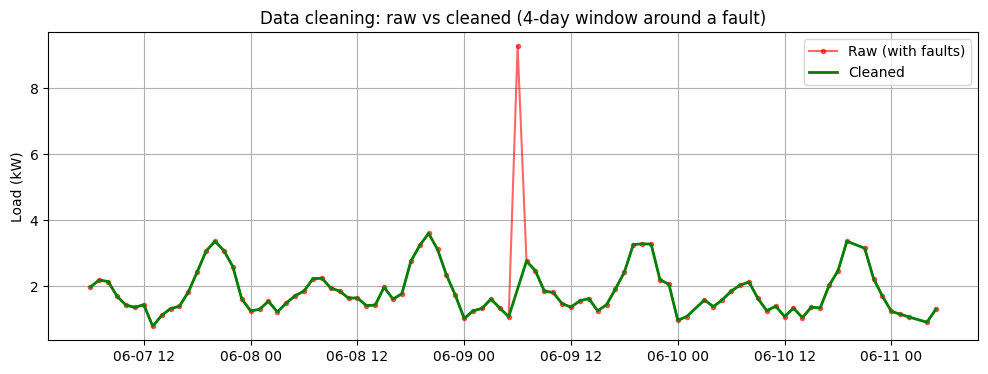

In [3]:
df = raw.copy()
print("Missing values before cleaning :", df.load.isna().sum())

# Outlier detection: how far is each value from the normal value for that hour? (z-score)
hr = df.time.dt.hour
mean_h = df.groupby(hr).load.transform("mean")
std_h = df.groupby(hr).load.transform("std")
z = (df.load - mean_h) / std_h
outliers = z.abs() > 4
print("Outliers (faulty spikes) found  :", int(outliers.sum()))

# Fix: remove outliers, then fill every gap using neighbouring hours
df.loc[outliers, "load"] = np.nan
df["load"] = df["load"].interpolate(limit_direction="both")
print("Missing values after cleaning  :", df.load.isna().sum())

# Visual proof: raw vs cleaned around the first spike
i = int(np.argmax(outliers.values))
a, b = max(0, i - 48), i + 48
plt.plot(raw.time[a:b], raw.load[a:b], "r.-", alpha=0.6, label="Raw (with faults)")
plt.plot(df.time[a:b], df.load[a:b], "g-", linewidth=2, label="Cleaned")
plt.title("Data cleaning: raw vs cleaned (4-day window around a fault)")
plt.ylabel("Load (kW)"); plt.legend(); plt.show()

## Step 4: Exploratory analysis (understanding usage patterns)
Before predicting, we check *when* electricity is used. Clear patterns = the load is predictable.

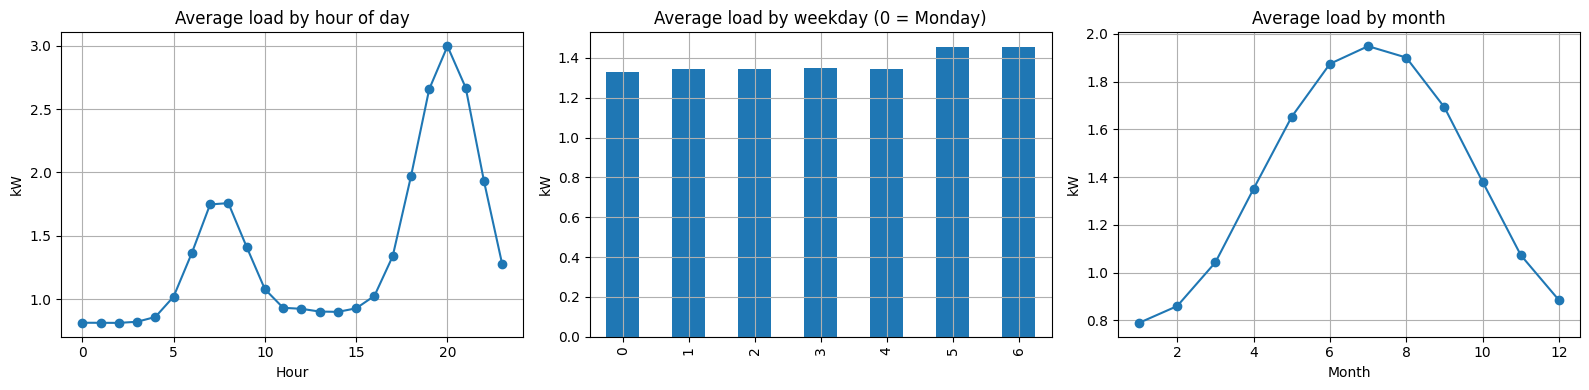

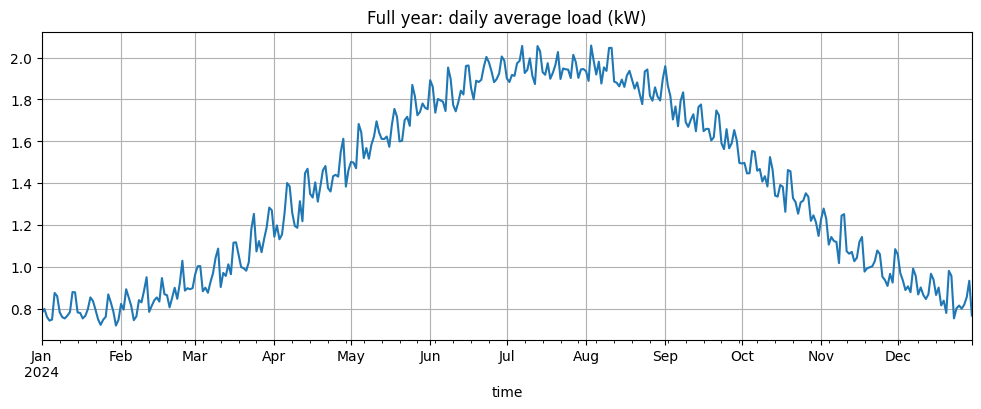

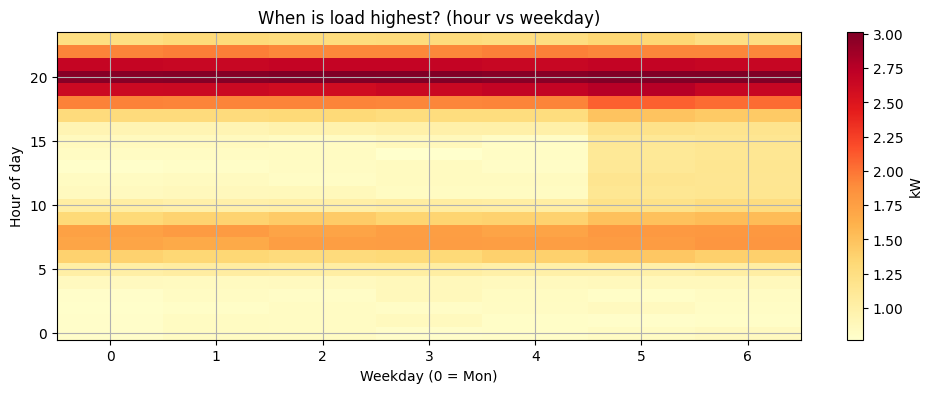

Top 4 peak hours of the day: [20, 21, 19, 18] (evening demand)


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.groupby(df.time.dt.hour).load.mean().plot(ax=ax[0], marker="o")
ax[0].set(title="Average load by hour of day", xlabel="Hour", ylabel="kW")
df.groupby(df.time.dt.dayofweek).load.mean().plot.bar(ax=ax[1])
ax[1].set(title="Average load by weekday (0 = Monday)", xlabel="", ylabel="kW")
df.groupby(df.time.dt.month).load.mean().plot(ax=ax[2], marker="o")
ax[2].set(title="Average load by month", xlabel="Month", ylabel="kW")
plt.tight_layout(); plt.show()

# Full-year view (daily average) + heatmap of hour vs weekday
df.set_index("time").load.resample("D").mean().plot(title="Full year: daily average load (kW)")
plt.show()

heat = df.pivot_table(index=df.time.dt.hour, columns=df.time.dt.dayofweek, values="load")
plt.imshow(heat, aspect="auto", cmap="YlOrRd", origin="lower")
plt.colorbar(label="kW"); plt.title("When is load highest? (hour vs weekday)")
plt.xlabel("Weekday (0 = Mon)"); plt.ylabel("Hour of day"); plt.show()

peak_hours = df.groupby(df.time.dt.hour).load.mean().sort_values(ascending=False).head(4)
print("Top 4 peak hours of the day:", list(peak_hours.index), "(evening demand)")

## Step 5: Feature engineering and train/test split
We give the model useful clues for each hour: time features and **past load values**
(1 hour ago, same hour yesterday, same hour last week).
We train on the **earlier 80%** of the year and test on the **later 20%**, because in real life
we predict the future from the past (a random split would leak future information).

In [5]:
d = df.copy()
d["hour"] = d.time.dt.hour
d["dayofweek"] = d.time.dt.dayofweek
d["month"] = d.time.dt.month
d["is_weekend"] = (d.dayofweek >= 5).astype(int)
d["lag_1"] = d.load.shift(1)       # 1 hour ago
d["lag_24"] = d.load.shift(24)     # same hour yesterday
d["lag_168"] = d.load.shift(168)   # same hour last week
d["roll_24"] = d.load.shift(1).rolling(24).mean()   # average of the last 24 hours
d = d.dropna().reset_index(drop=True)

FEATURES = ["hour", "dayofweek", "month", "is_weekend", "lag_1", "lag_24", "lag_168", "roll_24"]
split = int(len(d) * 0.8)
train, test = d.iloc[:split].copy(), d.iloc[split:].copy()

print("Features used :", FEATURES)
print(f"Training set  : {len(train)} hours  ({train.time.min().date()} to {train.time.max().date()})")
print(f"Testing set   : {len(test)} hours  ({test.time.min().date()} to {test.time.max().date()})")

Features used : ['hour', 'dayofweek', 'month', 'is_weekend', 'lag_1', 'lag_24', 'lag_168', 'roll_24']
Training set  : 6873 hours  (2024-01-08 to 2024-10-20)
Testing set   : 1719 hours  (2024-10-20 to 2024-12-30)


## Step 6: AI prediction models
We train several models and compare them with a simple **baseline** ("same as yesterday").
Metrics: **MAE** (average error, kW), **RMSE** (punishes big errors), **R2** (1.0 = perfect).

,Model,MAE,RMSE,R2
0,Gradient Boosting,0.157,0.195,0.918
1,Random Forest,0.164,0.205,0.909
2,Linear Regression,0.165,0.208,0.906
3,Baseline (yesterday),0.198,0.253,0.862


Best AI model: Gradient Boosting


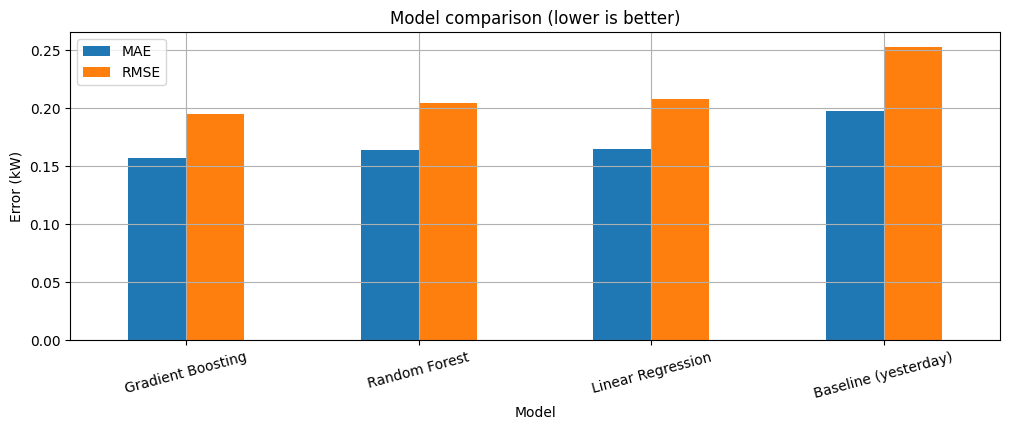

In [6]:
def evaluate(name, y, p):
    return {"Model": name, "MAE": mean_absolute_error(y, p),
            "RMSE": np.sqrt(mean_squared_error(y, p)), "R2": r2_score(y, p)}

preds, rows, fitted = {}, [], {}
preds["Baseline (yesterday)"] = test["lag_24"].values
rows.append(evaluate("Baseline (yesterday)", test.load, preds["Baseline (yesterday)"]))

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=150, max_depth=14, n_jobs=-1, random_state=0),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, max_depth=3, random_state=0),
}
for name, m in models.items():
    m.fit(train[FEATURES], train.load)
    fitted[name] = m
    preds[name] = m.predict(test[FEATURES])
    rows.append(evaluate(name, test.load, preds[name]))

table = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
display(table.round(3))

best = table[table.Model.isin(fitted)].iloc[0].Model
print(f"Best AI model: {best}")

table.set_index("Model")[["MAE", "RMSE"]].plot.bar(title="Model comparison (lower is better)")
plt.ylabel("Error (kW)"); plt.xticks(rotation=15); plt.show()

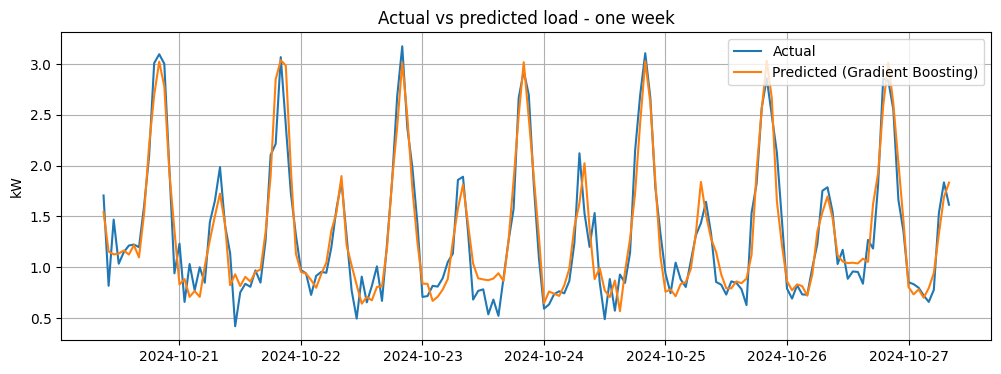

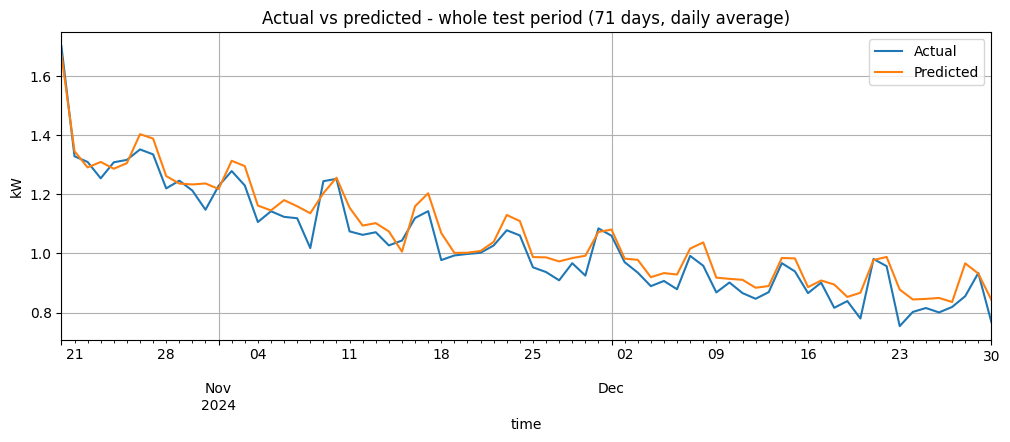

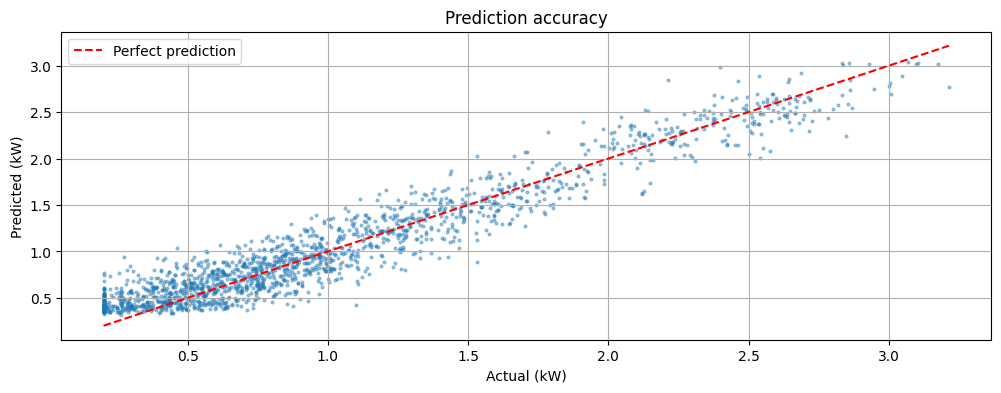

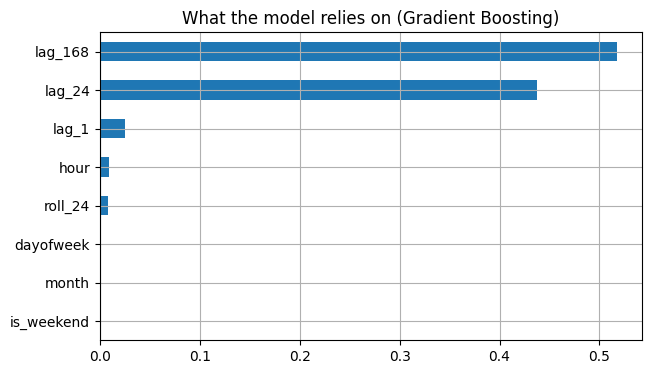

In [7]:
# How good are the predictions? Look at one week AND the whole test period
n = 24 * 7
plt.plot(test.time.values[:n], test.load.values[:n], label="Actual")
plt.plot(test.time.values[:n], preds[best][:n], label=f"Predicted ({best})")
plt.title("Actual vs predicted load - one week"); plt.ylabel("kW"); plt.legend(); plt.show()

daily = pd.DataFrame({"Actual": test.load.values, "Predicted": preds[best]}, index=test.time).resample("D").mean()
daily.plot(title=f"Actual vs predicted - whole test period ({len(test)//24} days, daily average)")
plt.ylabel("kW"); plt.show()

plt.scatter(test.load, preds[best], s=4, alpha=0.4)
lim = [test.load.min(), test.load.max()]
plt.plot(lim, lim, "r--", label="Perfect prediction")
plt.xlabel("Actual (kW)"); plt.ylabel("Predicted (kW)"); plt.title("Prediction accuracy"); plt.legend(); plt.show()

if hasattr(fitted[best], "feature_importances_"):
    pd.Series(fitted[best].feature_importances_, index=FEATURES).sort_values().plot.barh(
        title=f"What the model relies on ({best})", figsize=(7, 4)); plt.show()

## Step 7: Real-time load balancing (solar + battery)
The prediction is now **used to take decisions**. We simulate the system hour by hour (like real time):

1. Predict the coming hour's load (AI model).
2. If the predicted load is **above the peak threshold** -> discharge the battery to cut the peak.
3. If the predicted load is **low** -> charge the battery (only if it does not create a new peak).
4. Otherwise -> do nothing.

Solar panels reduce the load directly. A time-of-use tariff makes evening electricity more expensive.
The decision uses the **predicted** load, while the energy flow uses the **actual** load.

In [8]:
def solar_profile(times, peak_kw=2.0, seed=1):
    rng = np.random.default_rng(seed)
    h = times.dt.hour.values
    sun = np.clip(np.sin((h - 6) / 12 * np.pi), 0, None)
    return peak_kw * sun * rng.uniform(0.6, 1.0, len(h))

def tariff(times):                       # Rs per kWh (time-of-use pricing)
    h = times.dt.hour.values
    return np.where((h >= 18) & (h < 23), 10.0, np.where(h < 6, 4.0, 7.0))

# --- System settings (you can change these) ---
BATTERY_KWH, BATTERY_KW, EFFICIENCY, SOLAR_KW = 10.0, 3.0, 0.95, 2.0
HIGH_PCT, LOW_PCT = 80, 40               # threshold percentiles

# Thresholds learned from the TRAINING period only
train_net = np.clip(train.load.values - solar_profile(train.time, SOLAR_KW), 0, None)
high_thr, low_thr = np.percentile(train_net, HIGH_PCT), np.percentile(train_net, LOW_PCT)
print(f"Peak threshold (high): {high_thr:.2f} kW   |   Low-load threshold: {low_thr:.2f} kW")

t = test.time.reset_index(drop=True)
actual = test.load.values
pred = preds[best]
solar = solar_profile(t, SOLAR_KW)
price = tariff(t)
net_actual = np.clip(actual - solar, 0, None)
net_pred = np.clip(pred - solar, 0, None)

soc = BATTERY_KWH * 0.5                  # battery starts half full
grid, soc_log, action = [], [], []
for i in range(len(actual)):             # one step = one hour of "real time"
    load_now = net_actual[i]
    if net_pred[i] > high_thr and soc > 0.05 * BATTERY_KWH:
        d = min(BATTERY_KW, soc * EFFICIENCY, max(load_now - high_thr, 0))   # shave the peak
        soc -= d / EFFICIENCY; grid.append(load_now - d); action.append("Discharge")
    elif net_pred[i] < low_thr and soc < 0.95 * BATTERY_KWH:
        c = min(BATTERY_KW, (BATTERY_KWH - soc) / EFFICIENCY, max(high_thr - load_now, 0))
        soc += c * EFFICIENCY; grid.append(load_now + c); action.append("Charge")
    else:
        grid.append(load_now); action.append("Idle")
    soc_log.append(soc)

res = pd.DataFrame({"time": t, "actual": actual, "predicted": pred, "solar": solar,
                    "grid_with_system": np.array(grid), "battery_soc": soc_log,
                    "action": action, "price": price})
res["cost_before"] = res.actual * res.price
res["cost_after"] = res.grid_with_system * res.price

print("\nDecisions taken by the system over the test period:")
print(res.action.value_counts().to_string())
print("\nSample decisions (evening peak hours):")
display(res[res.time.dt.hour.isin([19, 20, 21])].head(6)[["time", "actual", "predicted", "action", "grid_with_system", "battery_soc"]].round({"actual": 2, "predicted": 2, "grid_with_system": 2, "battery_soc": 2}))

Peak threshold (high): 1.88 kW   |   Low-load threshold: 0.65 kW

Decisions taken by the system over the test period:
action
Idle         1387
Discharge     229
Charge        103

Sample decisions (evening peak hours):


,time,actual,predicted,action,grid_with_system,battery_soc
10,2024-10-20 19:00:00,3.01,2.69,Discharge,1.88,8.19
11,2024-10-20 20:00:00,3.10,3.02,Discharge,1.88,6.91
12,2024-10-20 21:00:00,3.00,2.78,Discharge,1.88,5.72
34,2024-10-21 19:00:00,2.21,2.85,Discharge,1.88,9.40
35,2024-10-21 20:00:00,3.07,3.04,Discharge,1.88,8.15
36,2024-10-21 21:00:00,2.40,2.98,Discharge,1.88,7.60


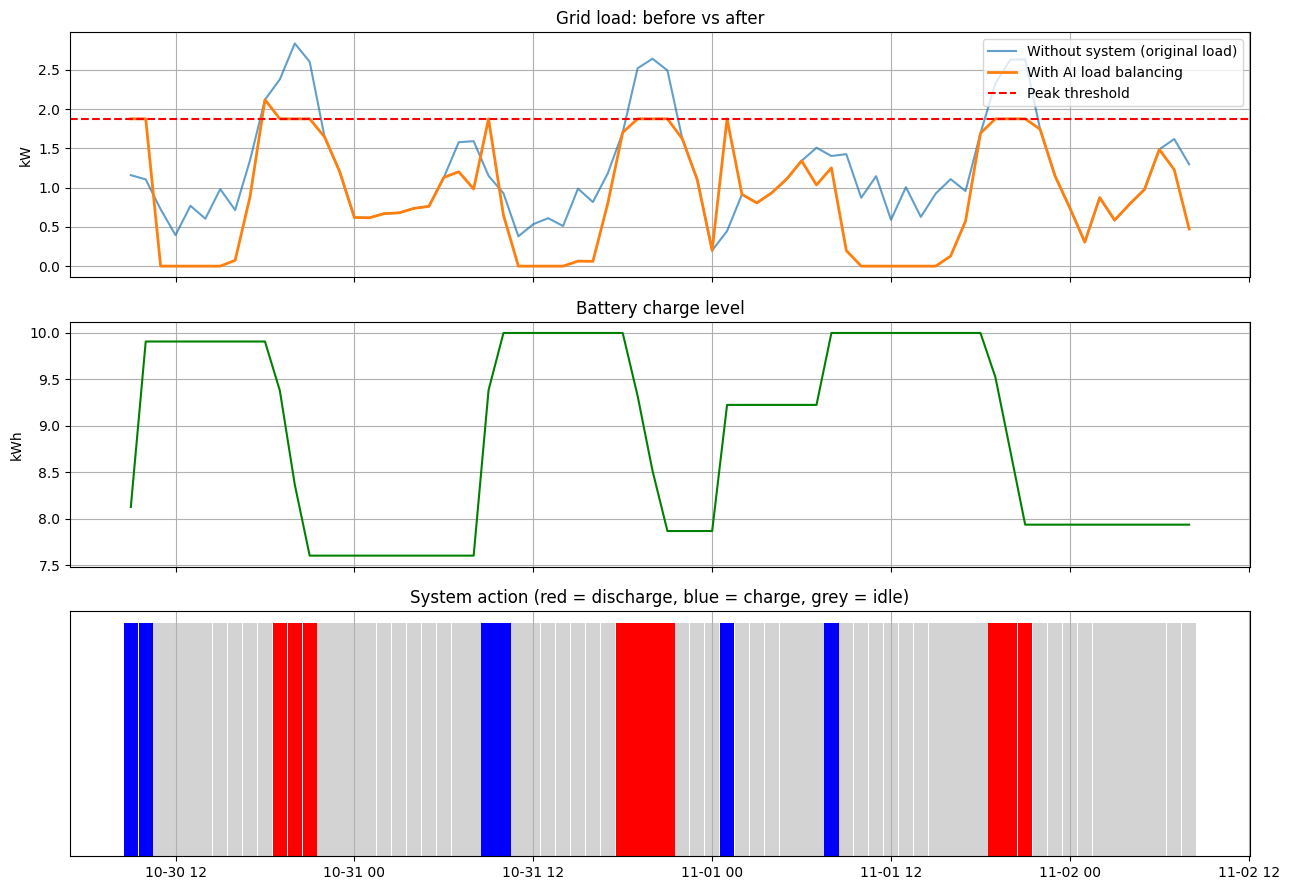

In [9]:
# Visual: 3 days of the system working
a, b = 24 * 10, 24 * 13
v = res.iloc[a:b]
fig, ax = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
ax[0].plot(v.time, v.actual, label="Without system (original load)", alpha=0.7)
ax[0].plot(v.time, v.grid_with_system, label="With AI load balancing", linewidth=2)
ax[0].axhline(high_thr, color="r", ls="--", label="Peak threshold")
ax[0].set_title("Grid load: before vs after"); ax[0].set_ylabel("kW"); ax[0].legend()
ax[1].plot(v.time, v.battery_soc, color="green"); ax[1].set_title("Battery charge level"); ax[1].set_ylabel("kWh")
colors = v.action.map({"Discharge": "red", "Charge": "blue", "Idle": "lightgrey"})
ax[2].bar(v.time, 1, width=0.04, color=colors); ax[2].set_yticks([])
ax[2].set_title("System action (red = discharge, blue = charge, grey = idle)")
plt.tight_layout(); plt.show()

## Step 8: Results - what did the system achieve?
We compare the **original load** with the **load after AI prediction + load balancing**
over the whole test period.

,Metric,Before (no system),After (AI + balancing),Improvement (%)
0,Maximum peak (kW),3.21,2.15,33.13
1,Average of top-5% peak hours (kW),2.70,1.89,30.09
2,Total energy cost (Rs),14000.30,10074.95,28.04


RESULT: peak load reduced by 33.1% and energy cost reduced by 28.0%


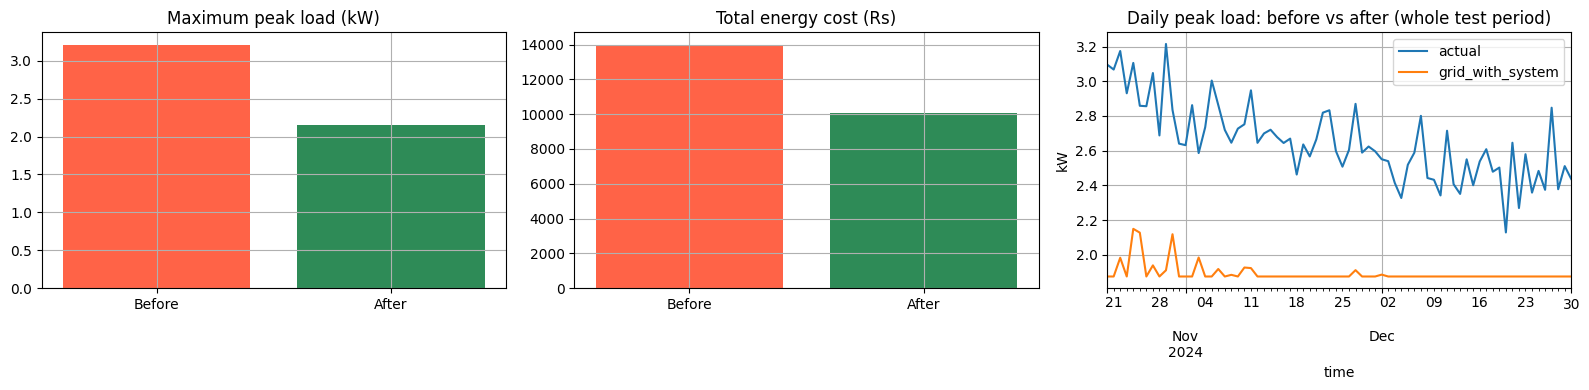

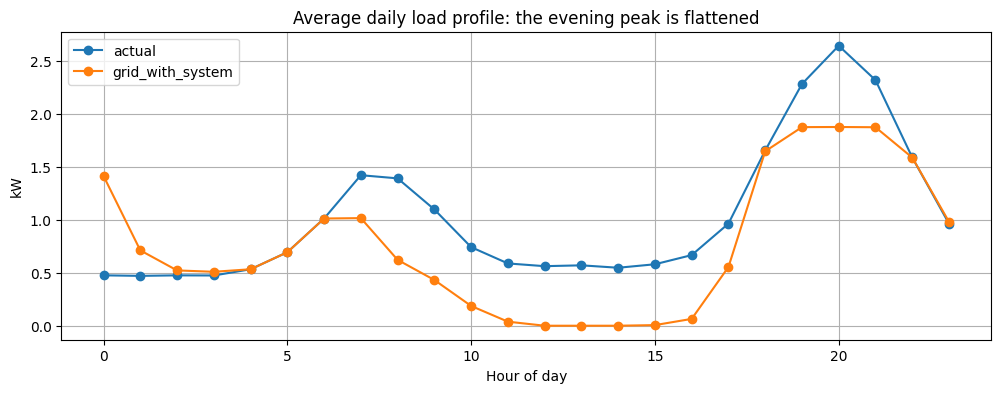

In [10]:
top5 = lambda x: np.sort(x)[-max(1, len(x) // 20):].mean()        # average of the worst 5% hours
summary = pd.DataFrame({
    "Metric": ["Maximum peak (kW)", "Average of top-5% peak hours (kW)", "Total energy cost (Rs)"],
    "Before (no system)": [res.actual.max(), top5(res.actual.values), res.cost_before.sum()],
    "After (AI + balancing)": [res.grid_with_system.max(), top5(res.grid_with_system.values), res.cost_after.sum()],
})
summary["Improvement (%)"] = 100 * (summary.iloc[:, 1] - summary.iloc[:, 2]) / summary.iloc[:, 1]
display(summary.round(2))

print(f"RESULT: peak load reduced by {summary.iloc[0,3]:.1f}% and energy cost reduced by {summary.iloc[2,3]:.1f}%")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].bar(["Before", "After"], summary.iloc[0, 1:3].astype(float), color=["tomato", "seagreen"])
ax[0].set_title("Maximum peak load (kW)")
ax[1].bar(["Before", "After"], summary.iloc[2, 1:3].astype(float), color=["tomato", "seagreen"])
ax[1].set_title("Total energy cost (Rs)")
dpeak = res.set_index("time")[["actual", "grid_with_system"]].resample("D").max()
dpeak.plot(ax=ax[2], title="Daily peak load: before vs after (whole test period)")
ax[2].set_ylabel("kW"); plt.tight_layout(); plt.show()

prof = res.groupby(res.time.dt.hour)[["actual", "grid_with_system"]].mean()
prof.plot(title="Average daily load profile: the evening peak is flattened", marker="o")
plt.xlabel("Hour of day"); plt.ylabel("kW"); plt.show()

## Remaining work (Steps 9 and 10)
* **Step 9 - Dashboard:** Streamlit web app showing live prediction, battery level, peak alerts and savings.
* **Step 10 - Final improvements:** replace sample data with the real UCI dataset, add an LSTM model,
  test on more scenarios (weekends, seasons), write the final report and presentation.

**Future scope:** real IoT smart meters, weather data as an input, cloud deployment, reinforcement learning for smarter balancing.